In [14]:
import os 
from dotenv import load_dotenv
load_dotenv()
api_key=os.environ["OPENROUTER_API_KEY"] = os.getenv("OPENROUTER_API_KEY")  
os.environ["TAVILY_API_KEY"] = os.getenv("TAVILY_API_KEY")
 

In [ ]:
from langchain.agents import create_agent
from langchain.agents.middleware import SummarizationMiddleware,HumanInTheLoopMiddleware
from langchain_openai import ChatOpenAI


In [ ]:


chat_model = ChatOpenAI(
    model="openai/gpt-4o-mini",
    api_key=os.environ["OPENROUTER_API_KEY"],
    base_url="https://openrouter.ai/api/v1"
)


## Summerization Middleware

In [ ]:
agent = create_agent(
    model="openrouter:openai/gpt-4o-mini",
    middleware=[
        SummarizationMiddleware(
            model=chat_model,
            trigger=("tokens", 1000),
            keep=("messages", 5),
        )
    ]
)


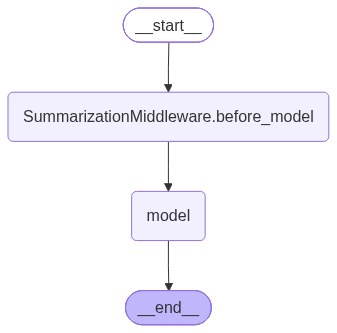

In [27]:
agent


In [28]:
response = agent.invoke({
    "messages": [
        {
            "role": "user",
            "content": "What are the latest developments in AI agents?"
        }
    ]
})


In [29]:
for msg in response["messages"]:
    msg.pretty_print()


================================ Human Message =================================

What are the latest developments in AI agents?
================================== Ai Message ==================================

As of October 2023, several notable developments in AI agents have emerged across various sectors. Here are some key trends and innovations:

1. **Generative AI Advancements**: Generative models like ChatGPT and others have seen improvements in their ability to produce coherent and contextually relevant text, images, and even audio. These advancements are being integrated into customer service, content creation, and design tools.

2. **Multi-Modal AI**: AI agents are increasingly capable of understanding and generating content across multiple modalities, such as combining text, images, and audio. This allows for richer interactions in applications like virtual assistants and content generation tools.

3. **Autonomous Agents**: There is a growing focus on developing autonomous ag

### Human in the Loop Middleware 

In [30]:
from tavily import TavilyClient

from typing import Literal
tavily_client=TavilyClient(api_key=os.environ["TAVILY_API_KEY"])


def web_search(query:str,max_results=5,topic:Literal["general","news","images","videos"]="general"):
    """
    Perform a web search using Tavily API.

    Args:
        query (str): The search query.
        max_results (int): Maximum number of results to return. Default is 5.
        topic (str): The topic of the search. Can be "general", "news", "images", or "videos". Default is "general".

    Returns:
        list: A list of search results.
    """
    try:
        results = tavily_client.search(query=query, max_results=max_results, topic=topic)
        return results
    except Exception as e:
        print(f"An error occurred during the web search: {e}")
        return []


In [ ]:
agent = create_agent(
    model="openrouter:openai/gpt-4o-mini",
    tools=[web_search],
    middleware=[
        HumanInTheLoopMiddleware(
            interrupt_on={
                "web_search": False # if True then it ask for permission from me 
            }
        )
    ]
)


In [ ]:
response = agent.invoke({
    "messages": [
        {
            "role": "user",
            "content": "What are the latest developments in AI agents?"
        }
    ]
})


In [40]:
for msg in response["messages"]:
    msg.pretty_print()


================================ Human Message =================================

What are the latest developments in AI agents?
================================== Ai Message ==================================
Tool Calls:
  web_search (call_ZVlpa7gOAXRJqnv1QfN8BRgU)
 Call ID: call_ZVlpa7gOAXRJqnv1QfN8BRgU
  Args:
    query: latest developments in AI agents
    max_results: 5
================================= Tool Message =================================
Name: web_search

{"query": "latest developments in AI agents", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://blog.mean.ceo/latest-ai-developments-news-june-2026", "title": "Latest AI developments News | June, 2026 (STARTUP EDITION)", "content": "Latest AI developments news in June 2026 shows a market that is getting sharper, more specialized, and less forgiving for founders who still treat AI like a shiny add-on. From my point of view as Violetta Bonenkamp, also known as Mean CEO, this month’s

### ModelRetryMiddleware -- useful retry failed model calls 
### ModelFallbackMiddleware -- Automatically fallback to alternative models when the primary model fails

In [ ]:
from langchain.agents import create_agent
from langchain.agents.middleware import ModelRetryMiddleware, ModelFallbackMiddleware

agent = create_agent(
    model="openrouter:openai/gpt-4o-mini",
    tools=[web_search],
    middleware=[
        ModelRetryMiddleware(
            max_retries=3,
            backoff_factor=2.0,
            initial_delay=1.0,
        ),
        ModelFallbackMiddleware(
            "openrouter:openai/gpt-5.4-mini",
        ),
    ],
)


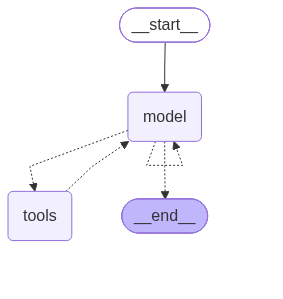

In [46]:
agent


### ModelCallLimitMiddleware -- Limit the number of model calls to prevent infinite loops

In [ ]:
from langchain.agents import create_agent
from langchain.agents.middleware import ModelCallLimitMiddleware
from langgraph.checkpoint.memory import InMemorySaver
agent = create_agent(
    model="openrouter:openai/gpt-4o-mini",
    checkpointer=InMemorySaver(),  # Required for thread limiting
    middleware=[
        ModelCallLimitMiddleware(
            thread_limit=10,
            run_limit=5,
            exit_behavior="end"
        )
    ],
)


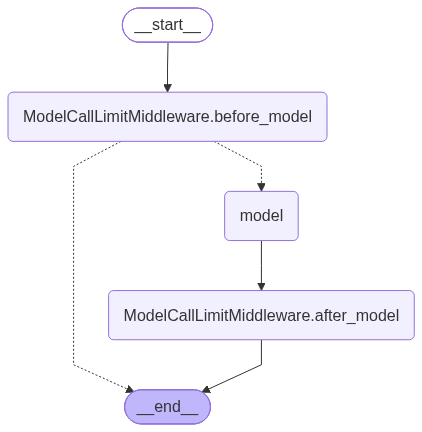

In [49]:
agent


### ToolCallLimitMiddleware -- Control agent execution by limiting the number of tool calls

In [ ]:
from langchain.agents import create_agent
from langchain.agents.middleware import ToolCallLimitMiddleware

agent = create_agent(
    model="openrouter:openai/gpt-4o-mini",
    tools=[web_search],
    middleware=[
        ToolCallLimitMiddleware(
            tool_name="web_search",
            run_limit=5
        )
    ]
)


## PIIMiddleware -- PII detection

In [ ]:
from langchain.agents import create_agent
from langchain.agents.middleware import PIIMiddleware

agent = create_agent(
    model="openrouter:openai/gpt-4o-mini",
    tools=[],
    middleware=[
        PIIMiddleware(
            "email",
            strategy="redact",
            apply_to_input=True,
        ),
        PIIMiddleware(
            "credit_card",
            strategy="mask",
            apply_to_input=True,
        ),
    ],
)


In [57]:
response = agent.invoke({
    "messages": [
        {
            "role": "user",
            "content": (
                "My email is test@example.com "
                "and my credit card is 4111 1111 1111 1111. "
                "Please tell me what information I provided."
            ),
        }
    ]
})

print(response["messages"][-1].content)


You've provided an email address and a partial credit card number. The email address has been redacted for privacy, and the credit card number is partially obscured (with only the last four digits shown). It's important to keep such information private and secure. If you have any concerns about privacy or security, please let me know!
